# QQR 2026 

In [3]:
%load_ext autoreload
%autoreload 2

## Yearly evolution

In [1]:
from pathlib import Path
from usagestats.bookingdb import BookingDB
from datetime import datetime, timedelta
import pytz
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from usagestats import visual

# For illustator export
# https://jonathansoma.com/lede/data-studio/matplotlib/exporting-from-matplotlib-to-open-in-adobe-illustrator/
import matplotlib

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

sns.set_context("paper")
sns.set_style("darkgrid")

db_file = "bookings.db"
folder = Path(
    "/run/user/1000/gvfs/smb-share:server=istore,share=microscopy_group_share,user=jeromeb/Admin/Usage Stats/2025"
)

local_tz = pytz.timezone("Europe/London")
start_date = datetime.fromisoformat("2017-01-01").replace(tzinfo=local_tz)
num_weeks = 9 * 52
end_date = start_date + timedelta(weeks=num_weeks)

drop_bookings_type = ["service", "maintenance", "training"]
drop_instrument = ["Analysis PC1", "Analysis PC2", "Analysis PC3", "Analysis PC4"]


# fix booking types
def get_type_from_str(x):
    types = {
        "serv": "service",
        "maint": "maintenance",
        "train": "training",
        "maintenace": "maintenance",
    }
    for y in types:
        if x.lower().find(y) >= 0:
            return types[y]
    return "imaging"


db_file = folder / "bookings.db"
drop_bookings_type = ["service", "maintenance", "training"]
drop_instrument = ["Analysis PC1", "Analysis PC2", "Analysis PC3", "Analysis PC4"]
drop_users = [
    "Nick Barry",
    "Jonathan Howe",
    "Matthias Pasche",
    "Ben Sutcliffe",
    "Sarah Lecinski",
    "Tomás Pais de Azevedo",
    "Jerome Boulanger",
]
with BookingDB(db_file) as db:
    bookings = db.get_events_in_range(start_date, end_date)

bookings["type"] = [get_type_from_str(x) for x in bookings["subject"]]

# Add periods
bookings["year"] = [pd.Period(x, freq="Y") for x in bookings["start"]]
bookings["year"] = bookings["year"].astype(str).astype(int)
bookings["quarter"] = [pd.Period(x, freq="Q") for x in bookings["start"]]
bookings["week"] = [pd.Period(x, freq="W") for x in bookings["start"]]

bookings.to_csv(folder / "20260908_qqr26_bookings.csv")

In [2]:
import numpy as np

for n, g in bookings.groupby("year"):
    print(n, g.iloc[np.argmax(g["hours"].sum())]["user"])

2017 Eva Kaulich
2018 Lucy Ginger
2019 Joy Staniforth
2020 Anais Portet
2021 Nathan Richoz
2022 Nathan Richoz
2023 Michal Eisenberg-Bord
2024 Antonio Pagan
2025 Mahmoud Bassal


By type

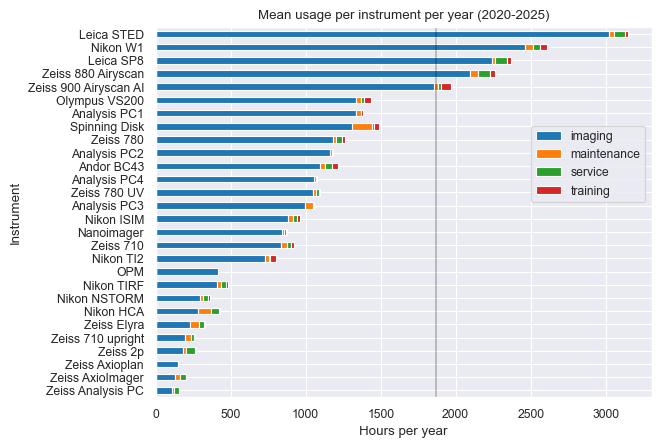

In [6]:
# Compute the sum usage per week per type per instrument

bookings_flt = bookings[bookings["year"]>=2020]
weekly_per_instruments_per_type = (
    bookings_flt.groupby(["instrument", "year", "type"], as_index=False)
    .agg(hours=("hours", "sum"))
    .groupby(["instrument", "type"])
    .agg(usage=("hours", "mean"))
    .reset_index()
    .pivot(index="instrument", values="usage", columns="type")
    .fillna(0)
    .sort_values("imaging")
)

weekly_per_instruments_per_type.to_csv(
    folder / "20260908_qqr26_booking-by-type-and-instrument.csv"
)

weekly_per_instruments_per_type.plot(kind="barh", stacked=True)
plt.legend(bbox_to_anchor=(1, 0.75))
plt.title(f"Mean usage per instrument per year ({bookings_flt['year'].min()}-{bookings_flt['year'].max()})")
plt.xlabel("Hours per year")
plt.ylabel("Instrument")
plt.gca().axvline(7.2*52*5,alpha=0.25,color="black")
plt.savefig(
    folder / "20260908_qqr26_usage-per-type-per-instrument.pdf",
    pad_inches=1.2,
    bbox_inches="tight",
)


Exclude special booking

In [ ]:
# excludes special bookings
bookings = bookings[~bookings["type"].isin(drop_bookings_type)]
# excludes instruments
bookings = bookings[~bookings["instrument"].isin(drop_instrument)]

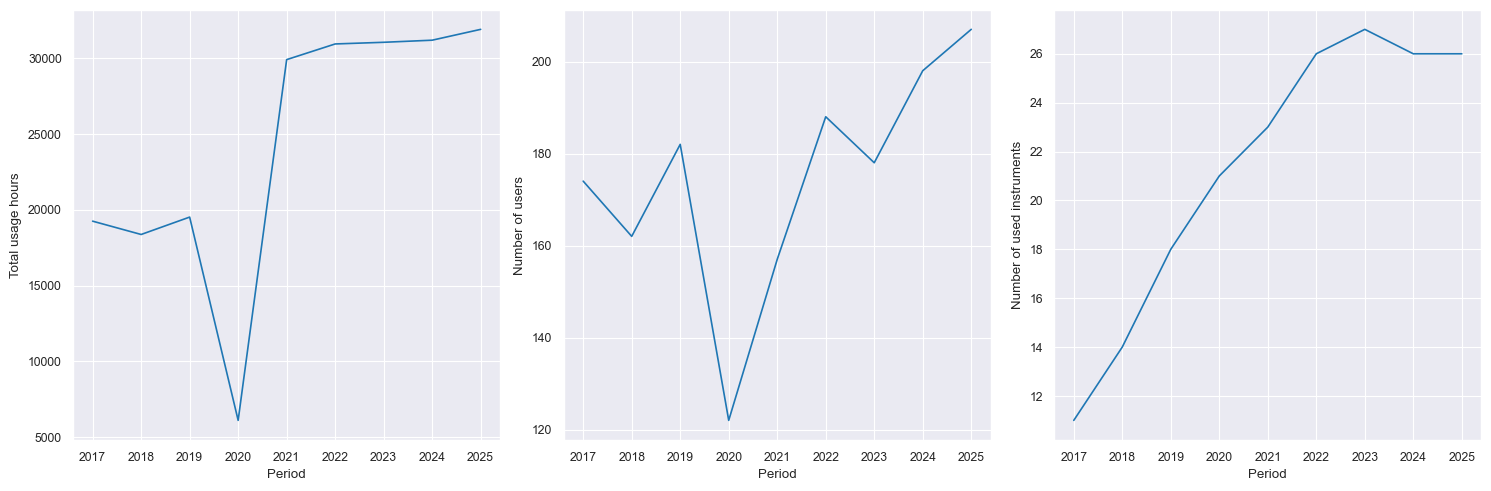

In [20]:
yearly = (
    bookings.groupby("year")
    .agg(
        instrument=("instrument", "nunique"),
        hours=("hours", "sum"),
        user=("user", "nunique"),
    )
    .reset_index()
)

yearly.to_csv(folder / "20260908_qqr26_yearly.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
yearly.plot(x="year", y="hours", ax=ax[0], legend=None).set(
    xlabel="Period", ylabel="Total usage hours"
)
yearly.plot(x="year", y="user", ax=ax[1], legend=None).set(
    xlabel="Period", ylabel="Number of users"
)
yearly.plot(x="year", y="instrument", ax=ax[2], legend=None).set(
    xlabel="Period", ylabel="Number of used instruments"
)
plt.tight_layout()
plt.savefig(folder / "20260908_qqr26_yearly.pdf", transparent=True, bbox_inches="tight")

Quaterly

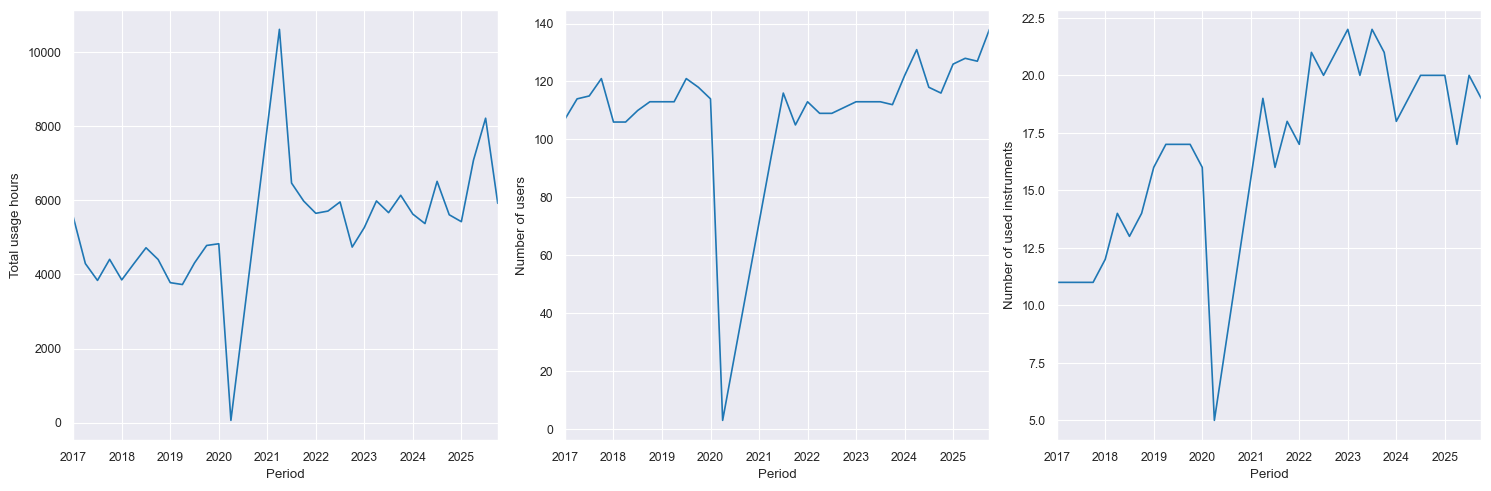

In [ ]:
quartely = (
    bookings.groupby("quarter", observed=True).agg(
        instrument=("instrument", "nunique"),
        hours=("hours", "sum"),
        user=("user", "nunique"),
    )
).reset_index()

quartely.to_csv(folder / "20260908_qqr26_quarterly.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
quartely.plot(x="quarter", y="hours", ax=ax[0], legend=None).set(
    xlabel="Period", ylabel="Total usage hours"
)
quartely.plot(x="quarter", y="user", ax=ax[1], legend=None).set(
    xlabel="Period", ylabel="Number of users"
)
quartely.plot(x="quarter", y="instrument", ax=ax[2], legend=None).set(
    xlabel="Period", ylabel="Number of used instruments"
)
plt.tight_layout()
plt.savefig(
    folder / "20260908_qqr26_quarterly.pdf", transparent=True, bbox_inches="tight"
)


## Weekly use in 2025

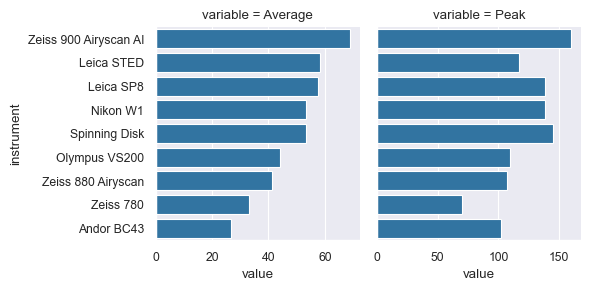

In [ ]:
bookings25 = bookings[bookings["year"] == 2025]

# compute weekly hour total usage and then compute the average per instrument
weekly_per_instruments = (
    bookings25.groupby(["instrument", "week"])
    .agg(hours=("hours", "sum"))
    .groupby("instrument")
    .agg(Average=("hours", "mean"), Peak=("hours", "max"), Total=("hours", "sum"))
    .reset_index()
    .sort_values(by="Total", ascending=False)
)
weekly_per_instruments.to_csv(folder / "20260908_qqr26_weekly_2025.csv")
# select 10 firsts
weekly_per_instruments = weekly_per_instruments.iloc[:9]
# melt the dataframe
weekly_per_instruments_melted = weekly_per_instruments.melt(
    id_vars="instrument", value_vars=("Average", "Peak")
)

g = sns.FacetGrid(weekly_per_instruments_melted, col="variable", sharex=False)
g.map_dataframe(sns.barplot, y="instrument", x="value")
plt.savefig(
    folder / "20260908_qqr26_weekly_2025.pdf", transparent=True, bbox_inches="tight"
)

## Final figure

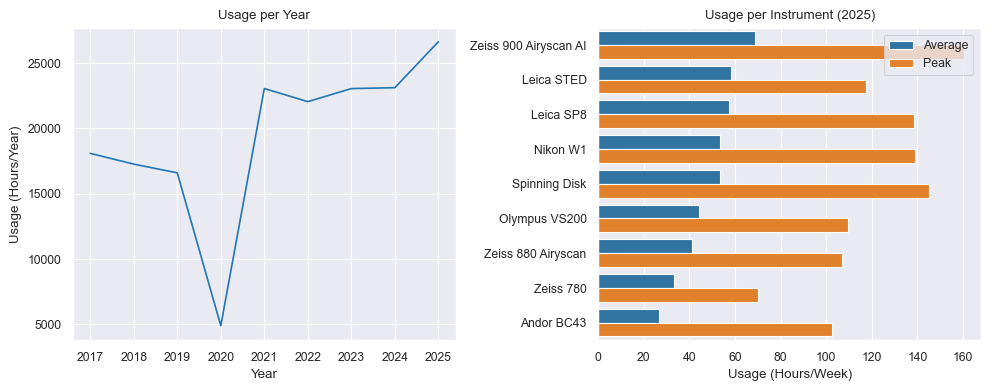

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.lineplot(yearly, x="year", y="hours", ax=ax[0]).set(
    title="Usage per Year", xlabel="Year", ylabel="Usage (Hours/Year)"
)
sns.barplot(
    weekly_per_instruments_melted, y="instrument", x="value", hue="variable"
).set(
    title="Usage per Instrument (2025)",
    ylabel="",
    xlabel="Usage (Hours/Week)",
    xlim=[0, 168],
)
sns.move_legend(
    ax[1],
    "upper right",
    bbox_to_anchor=(0.995, 0.995),
    ncol=1,
    title=None,
    frameon=True,
)
plt.tight_layout()
plt.savefig(folder / "20260908_qqr26_final.pdf", bbox_inches="tight")

/tmp/ipykernel_154622/213084804.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["year", "division"])["hours"]


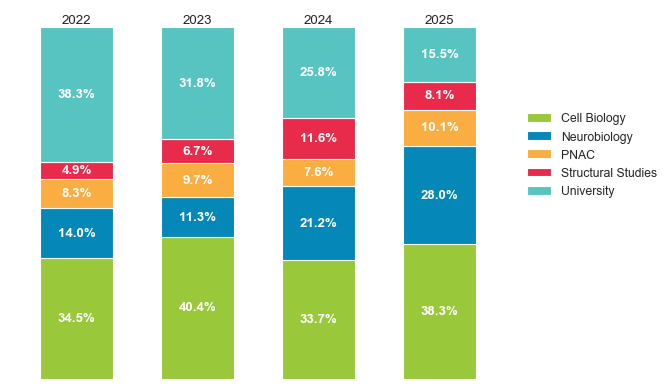

In [ ]:
from matplotlib import colormaps, colors

set3 = plt.get_cmap("Set1")
first_5_colors = colors.ListedColormap(
    [
        (60 / 100, 79 / 100, 23 / 100),
        (2 / 100, 53 / 100, 71.8 / 100),
        (98 / 100, 68 / 100, 25.1 / 100),
        (91 / 100, 17 / 100, 29 / 100),
        (34 / 100, 77 / 100, 76 / 100),
    ]
)
sns.set_style("white")
bookings = bookings[bookings["division"] != "Unknown"]
bookings["division"] = pd.Categorical(bookings["division"])
usage_per_division = (
    bookings[bookings["year"] > 2021]
    .groupby(["year", "division"])["hours"]
    .sum()
    .to_frame()
)
total_usage_per_division_per_year = (
    usage_per_division.groupby("year")["hours"]
    .sum()
    .to_frame()
    .rename(columns={"hours": "total"})
)
usage_per_division.merge(total_usage_per_division_per_year, on="year", how="left")
usage_per_division["percentage"] = (
    100 * usage_per_division["hours"] / total_usage_per_division_per_year["total"]
).round(1)

pivot_df = usage_per_division.reset_index().pivot(
    index="year", columns="division", values="percentage"
)
ax = pivot_df.plot(kind="bar", stacked=True, width=0.6, cmap=first_5_colors)
for container in ax.containers:
    ax.bar_label(
        container, fmt="%.1f%%", label_type="center", color="white", weight="bold"
    )
ax.legend(bbox_to_anchor=(1.02, 0.75), frameon=False)

for k, x in enumerate(pivot_df.index):
    ax.text(k, 101, f"{x}", fontdict={"ha": "center"})

plt.box(False)
plt.gca().axis("off")
plt.savefig(
    folder / "20260908_qqr26_usage_per_division.pdf",
    transparent=True,
    bbox_inches="tight",
)

/tmp/ipykernel_154622/2764787934.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["year", "division"])["hours"]


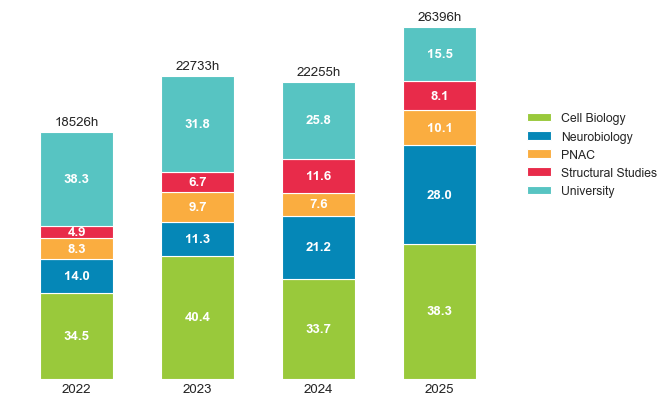

In [ ]:
from matplotlib import colors

# Get the color from MS graphs from Manu
set3 = plt.get_cmap("Set1")
first_5_colors = colors.ListedColormap(
    [
        (60 / 100, 79 / 100, 23 / 100),
        (2 / 100, 53 / 100, 71.8 / 100),
        (98 / 100, 68 / 100, 25.1 / 100),
        (91 / 100, 17 / 100, 29 / 100),
        (34 / 100, 77 / 100, 76 / 100),
    ]
)
sns.set_style("white")
bookings = bookings[bookings["division"] != "Unknown"]
bookings["division"] = pd.Categorical(bookings["division"])
usage_per_division = (
    bookings[bookings["year"] > 2021]
    .groupby(["year", "division"])["hours"]
    .sum()
    .to_frame()
)
total_usage_per_division_per_year = (
    usage_per_division.groupby("year")["hours"]
    .sum()
    .to_frame()
    .rename(columns={"hours": "total"})
)
usage_per_division.merge(total_usage_per_division_per_year, on="year", how="left")
usage_per_division["percentage"] = (
    100 * usage_per_division["hours"] / total_usage_per_division_per_year["total"]
).round(1)

pivot_df = usage_per_division.reset_index().pivot(
    index="year", columns="division", values="hours"
)
ax = pivot_df.plot(kind="bar", stacked=True, width=0.6, cmap=first_5_colors)
percentage = usage_per_division.reset_index().pivot(
    index="year", columns="division", values="percentage"
)
for k, container in enumerate(ax.containers):
    labels = percentage.iloc[:, k]
    ax.bar_label(
        container,
        labels,
        fmt="%.1f%%",
        label_type="center",
        color="white",
        weight="bold",
    )

ax.legend(bbox_to_anchor=(1.02, 0.75), frameon=False)

for k, x in enumerate(pivot_df.index):
    ax.text(k, -1000, f"{x}", fontdict={"ha": "center"})

for k, x in enumerate(pivot_df.T.sum()):
    ax.text(k, x + 500, f"{x:.0f}h", fontdict={"ha": "center"})

plt.box(False)
plt.gca().axis("off")

plt.savefig(
    folder / "20260908_qqr26_stackplot.pdf", transparent=True, bbox_inches="tight"
)

Using seaborn to produce the same graph

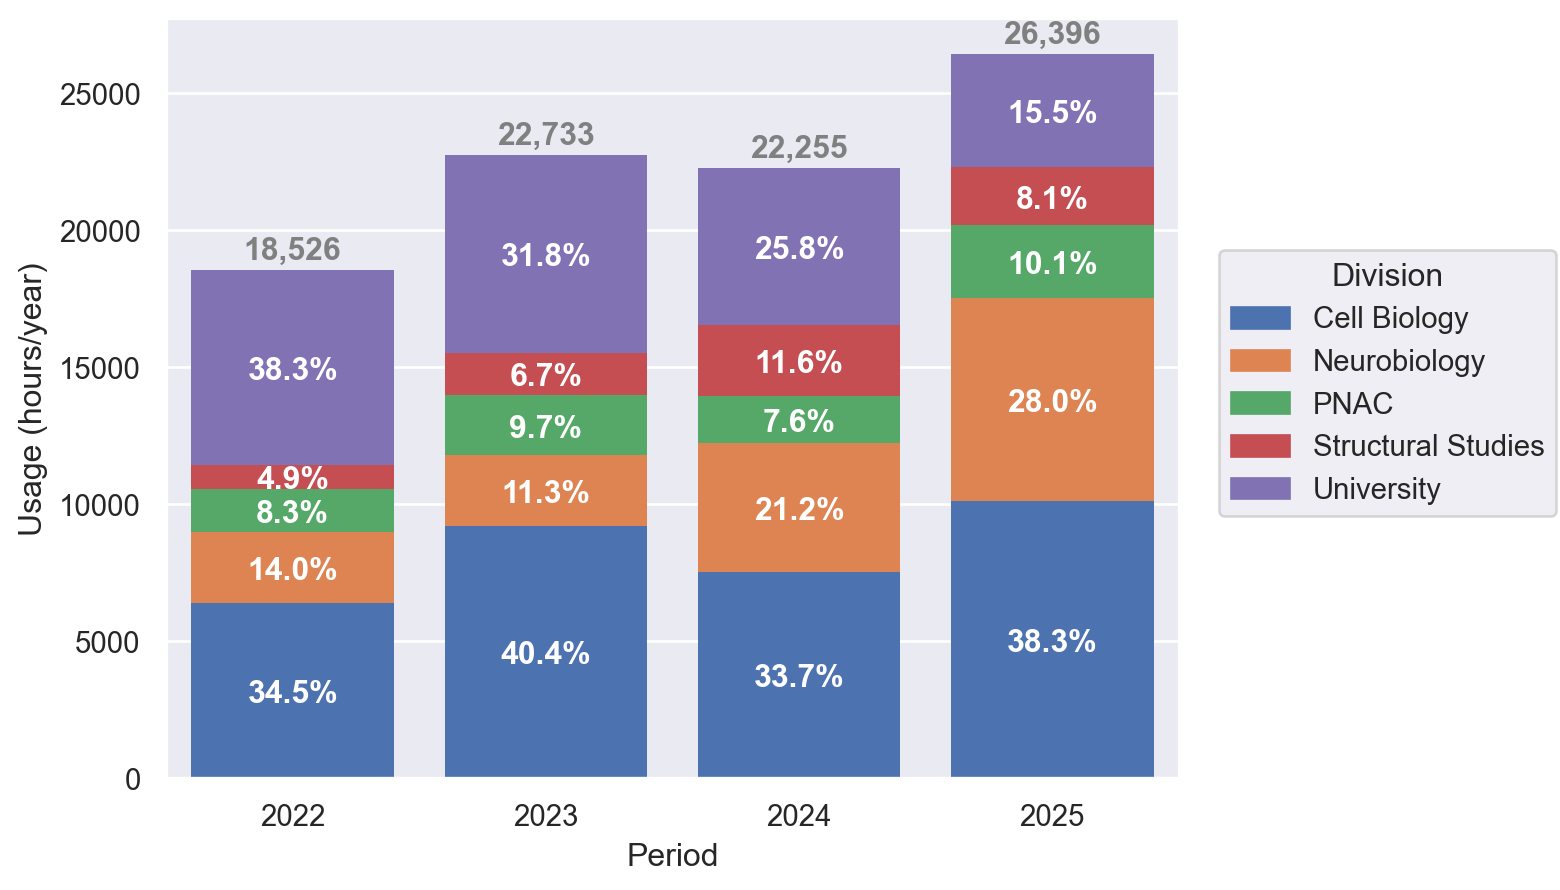

In [ ]:
import seaborn.objects as so
from matplotlib import style

# Sort the data
df_sorted = usage_per_division.sort_values(["year", "division"])
# Compute the top edge and the middle point of each segment
df_sorted["running_total"] = df_sorted.groupby("year")["hours"].cumsum()
df_sorted["text_y_center"] = df_sorted["running_total"] - (df_sorted["hours"] / 2)
df_sorted["percentage_text"] = df_sorted["percentage"].apply(lambda x: f"{x:.1f}%")
totals_per_year = df_sorted.groupby("year")["running_total"].transform("max")
df_sorted["total_hours_text"] = df_sorted.apply(
    lambda row: (
        f"{totals_per_year[row.name]:,.0f}"
        if row["running_total"] == totals_per_year[row.name]
        else ""
    ),
    axis=1,
)

df_sorted.reset_index(inplace=True)
df_sorted.rename(
    columns={"year": "Period", "hours": "Usage (hours/year)", "division": "Division"},
    inplace=True,
)
# Create the figure with the declarative mode
df_sorted["Period"] = pd.Categorical(df_sorted["Period"])
p = (
    so.Plot(
        df_sorted,
        x="Period",
        color="Division",
        y="Usage (hours/year)",
        text="percentage_text",
    )
    .add(so.Bar(alpha=1), so.Stack())
    .add(
        so.Text(artist_kws={"weight": "bold"}, color="w", halign="center"),
        y="text_y_center",
    )
    .add(
        so.Text(artist_kws={"weight": "bold"}, color="gray", valign="bottom", offset=2),
        y="running_total",
        text="total_hours_text",
        color=None,
    )
)
p.save(folder / "20260908_qqr26_stackplot_v2.pdf", bbox_inches="tight")
p


In [97]:
df_sorted["Division"].unique()

['Cell Biology', 'Neurobiology', 'PNAC', 'Structural Studies', 'University']
Categories (5, object): ['Cell Biology', 'Neurobiology', 'PNAC', 'Structural Studies', 'University']